# Projet 2 — Détecter des attaques réseau avec le Machine Learning
**FALL Madiagne**


## 1. Exploration

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
df = pd.read_csv("data/flux_train.csv")
print("Taille :", df.shape)
df.head()

Taille : (3000, 10)


,duration,protocol,dst_port,src_bytes,dst_bytes,nb_packets,nb_failed_logins,nb_conn_same_host,syn_rate,attaque
0,0.520,TCP,6402,22,2,1,0,42,0.841,1
1,0.509,TCP,8080,303,6038,15,0,4,0.149,0
2,0.377,TCP,23,4333,92,18,15,6,0.260,1
3,1.583,UDP,22,659,229,20,0,5,0.040,0
4,NaN,UDP,8080,5718,3953,12,0,6,0.128,0


In [2]:
print("Valeurs manquantes :")
print(df.isna().sum())
print()
print("Répartition de la cible (attaque) :")
print(df["attaque"].value_counts())
print(df["attaque"].value_counts(normalize=True).round(3))

Valeurs manquantes :
duration             90
protocol              0
dst_port              0
src_bytes             0
dst_bytes             0
nb_packets            0
nb_failed_logins      0
nb_conn_same_host     0
syn_rate              0
attaque               0
dtype: int64

Répartition de la cible (attaque) :
attaque
0    2167
1     833
Name: count, dtype: int64
attaque
0    0.722
1    0.278
Name: proportion, dtype: float64


In [3]:
# Les attaques se distinguent déjà par leurs moyennes
df.groupby("attaque").mean(numeric_only=True).T.round(2)

attaque,0,1
duration,4.07,1.50
dst_port,970.40,1943.48
src_bytes,2020.87,1762.73
dst_bytes,4705.98,533.10
nb_packets,19.17,56.78
nb_failed_logins,0.16,3.33
nb_conn_same_host,5.29,30.00
syn_rate,0.12,0.44


## 2. Prétraitement (dans un `Pipeline`)
- variables numériques : imputation par la médiane, puis mise à l'échelle
- `protocol` : encodage one-hot

In [4]:
X = df.drop(columns="attaque")
y = df["attaque"]
colonnes_num = [c for c in X.columns if c != "protocol"]


def creer_pipeline(modele):
    prepro = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), colonnes_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["protocol"]),
    ])
    return Pipeline([("prepro", prepro), ("modele", modele)])

## 3. Entraînement et comparaison de 3 modèles
On sépare un jeu de validation (20 %, stratifié pour garder ≈ 28 % d'attaques). Les classes sont déséquilibrées : on regarde le **F1 de la classe attaque**, pas l'accuracy.

In [5]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

modeles = {
    "Régression logistique": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Arbre de décision": DecisionTreeClassifier(max_depth=6, class_weight="balanced",
                                                random_state=RANDOM_STATE),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                              random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
lignes, pipelines = [], {}
for nom, modele in modeles.items():
    pipe = creer_pipeline(modele).fit(X_tr, y_tr)
    pred = pipe.predict(X_val)
    pipelines[nom] = pipe
    lignes.append({
        "Modèle": nom,
        "F1 (attaque)": f1_score(y_val, pred),
        "Rappel (attaque)": recall_score(y_val, pred),
        "Précision (attaque)": precision_score(y_val, pred),
        "F1 validation croisée (5 plis)": cross_val_score(
            creer_pipeline(modele), X, y, cv=cv, scoring="f1").mean(),
    })

resultats = pd.DataFrame(lignes).set_index("Modèle").round(3)
resultats

,F1 (attaque),Rappel (attaque),Précision (attaque),F1 validation croisée (5 plis)
Modèle,,,,
Régression logistique,0.920,0.898,0.943,0.896
Arbre de décision,0.953,0.964,0.942,0.935
Forêt aléatoire,0.976,0.976,0.976,0.958


## 4. Évaluation détaillée

In [6]:
for nom, pipe in pipelines.items():
    print("=" * 60)
    print(nom)
    print(classification_report(y_val, pipe.predict(X_val),
                                target_names=["normal (0)", "attaque (1)"]))

Régression logistique
              precision    recall  f1-score   support

  normal (0)       0.96      0.98      0.97       433
 attaque (1)       0.94      0.90      0.92       167

    accuracy                           0.96       600
   macro avg       0.95      0.94      0.95       600
weighted avg       0.96      0.96      0.96       600

Arbre de décision
              precision    recall  f1-score   support

  normal (0)       0.99      0.98      0.98       433
 attaque (1)       0.94      0.96      0.95       167

    accuracy                           0.97       600
   macro avg       0.96      0.97      0.97       600
weighted avg       0.97      0.97      0.97       600

Forêt aléatoire
              precision    recall  f1-score   support

  normal (0)       0.99      0.99      0.99       433
 attaque (1)       0.98      0.98      0.98       167

    accuracy                           0.99       600
   macro avg       0.98      0.98      0.98       600
weighted avg      

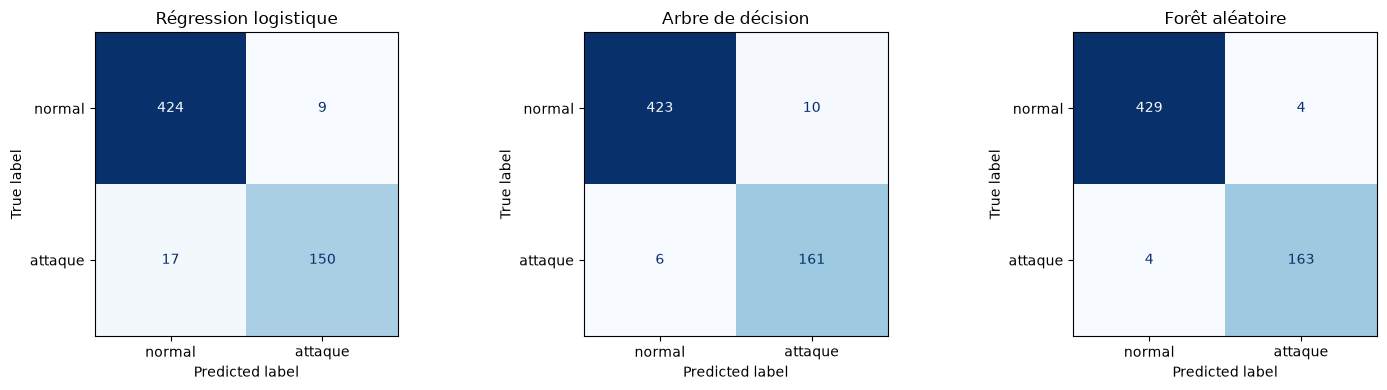

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, pipe) in zip(axes, pipelines.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_val, y_val, display_labels=["normal", "attaque"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

## 5. Choix du meilleur modèle

In [8]:
meilleur_nom = resultats["F1 (attaque)"].idxmax()
print("Meilleur modèle (F1 attaque sur validation) :", meilleur_nom)
print(resultats.loc[meilleur_nom])

Meilleur modèle (F1 attaque sur validation) : Forêt aléatoire
F1 (attaque)                      0.976
Rappel (attaque)                  0.976
Précision (attaque)               0.976
F1 validation croisée (5 plis)    0.958
Name: Forêt aléatoire, dtype: float64


## 6. Ré-entraînement sur toutes les données et sauvegarde

In [9]:
modele_final = creer_pipeline(modeles[meilleur_nom]).fit(X, y)
Path("models").mkdir(exist_ok=True)
joblib.dump(modele_final, "models/model.joblib")
print("Modèle enregistré dans models/model.joblib")

Modèle enregistré dans models/model.joblib


## 7. `src/predict.py`
Cette cellule écrit le fichier avec la fonction `predict` exigée.

In [15]:
Path("src").mkdir(exist_ok=True)
Path("src/predict.py").write_text('''"""Prédiction : charge models/model.joblib et prédit 0 (normal) ou 1 (attaque)."""
from pathlib import Path

import joblib
import pandas as pd

MODEL_PATH = Path(__file__).resolve().parent.parent / "models" / "model.joblib"
_model = None


def predict(df: pd.DataFrame) -> list:
    """df : mêmes colonnes que flux_train.csv, SANS 'attaque'.
    Retourne une liste de 0 (normal) ou 1 (attaque), une valeur par ligne."""
    global _model
    if _model is None:
        _model = joblib.load(MODEL_PATH)
    return [int(p) for p in _model.predict(df)]
''', encoding="utf-8")
print("src/predict.py écrit")

src/predict.py écrit


In [11]:
# Test de predict() : on recharge le fichier depuis le disque
import importlib.util
spec = importlib.util.spec_from_file_location("predict_mod", "src/predict.py")
predict_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(predict_mod)

essai = predict_mod.predict(X.head(10))
print(essai)
print("Une valeur par ligne :", len(essai) == 10)

[1, 0, 1, 0, 0, 1, 1, 1, 0, 0]
Une valeur par ligne : True


## 8. Analyse des erreurs (modèle retenu, jeu de validation)

In [12]:
pred_val = pipelines[meilleur_nom].predict(X_val)
tn, fp, fn, tp = confusion_matrix(y_val, pred_val).ravel()
print(f"Vrais positifs (attaques détectées) : {tp}")
print(f"Faux négatifs (attaques ratées)      : {fn}  sur {tp + fn} attaques")
print(f"Faux positifs (fausses alertes)      : {fp}  sur {tn + fp} flux normaux")

erreurs = X_val[pred_val != y_val].assign(vrai=y_val[pred_val != y_val],
                                          predit=pred_val[pred_val != y_val])
erreurs

Vrais positifs (attaques détectées) : 165
Faux négatifs (attaques ratées)      : 2  sur 167 attaques
Faux positifs (fausses alertes)      : 2  sur 433 flux normaux


,duration,protocol,dst_port,src_bytes,dst_bytes,nb_packets,nb_failed_logins,nb_conn_same_host,syn_rate,vrai,predit
1400,2.745,UDP,80,118,440,16,0,6,0.198,1,0
2422,0.057,TCP,8730,71,9,5,0,46,0.902,0,1
2325,0.221,ICMP,80,2919,36,11,0,2,0.072,1,0
775,0.007,TCP,22,825,175,16,9,12,0.335,0,1


**À rédiger dans le README** (avec tes mots) :
- un **faux négatif** est une attaque que l'IDS laisse passer : l'intrus n'est pas détecté et l'attaque peut réussir sans alerte. C'est le pire cas en sécurité ;
- un **faux positif** est une fausse alerte : cela fait perdre du temps aux analystes, mais ne laisse entrer personne ;
- regarde le tableau `erreurs` ci-dessus pour voir quels types de flux sont confondus.

## 9. Tableau à copier dans la section « Résultats » du README

In [13]:
def pct(x):
    return f"{x:.3f}"

print("| Modèle | F1 (attaque) | Rappel (attaque) | Précision (attaque) |")
print("|---|---|---|---|")
for nom, r in resultats.iterrows():
    print(f"| {nom} | {pct(r['F1 (attaque)'])} | {pct(r['Rappel (attaque)'])} | {pct(r['Précision (attaque)'])} |")

| Modèle | F1 (attaque) | Rappel (attaque) | Précision (attaque) |
|---|---|---|---|
| Régression logistique | 0.920 | 0.898 | 0.943 |
| Arbre de décision | 0.953 | 0.964 | 0.942 |
| Forêt aléatoire | 0.976 | 0.976 | 0.976 |


In [14]:
import sklearn, numpy, pandas, joblib
print(f"pandas=={pandas.__version__}")
print(f"numpy=={numpy.__version__}")
print(f"scikit-learn=={sklearn.__version__}")
print(f"joblib=={joblib.__version__}")
print("(copie ces lignes dans requirements.txt ; ajoute matplotlib si tu gardes les figures)")

pandas==3.0.5
numpy==2.5.3
scikit-learn==1.9.1
joblib==1.6.0
(copie ces lignes dans requirements.txt ; ajoute matplotlib si tu gardes les figures)
